In [10]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)


def softmax(Z):
    Z = Z - np.max(Z, axis=1, keepdims=True)
    E_z = np.exp(Z)
    return E_z / np.sum(E_z, axis=1, keepdims=True)


def train(X, labels, K, lr=0.1, epochs=500):
    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]       
    ##eye는 K X K 행렬이고 Lables에 있는 정수는 행마다 one hot
    #encoding의 위치를 출력 (m, K) one-hot

    history = []

    for ep in range(epochs):
        # forward (루프 안!)
        Z = X @ W.T + b            # (m, K)
        P = softmax(Z)             # (m, K)

        # loss
        loss = -np.sum(Y * np.log(P + 1e-12)) / m
        history.append(loss)

        # backward
        # backward is always same in GLM
        dW = (P - Y).T @ X / m     # (K, i)
        db = (P - Y).mean(axis=0)  # (K,)
        assert dW.shape == W.shape and db.shape == b.shape

        # update
        W = W - lr * dW
        b = b - lr * db

    return W, b, history

def train_batch(X,batch_size, labels, K, lr=0.1, epochs=500,seed = 42):

    m, i = X.shape
    W = np.zeros((K, i))
    b = np.zeros(K)
    Y = np.eye(K)[labels]
    rng = np.random.default_rng(seed)

    history = []

    for epoch in range(epochs):

        idx = rng.permutation(m)

        for start in range(0,m,batch_size):

            batch = idx[start:start+batch_size]

            Xb = X[batch] #(B,i)
            Yb = Y[batch] #(B,K)
            
            B= len(batch)

            P = softmax(Xb @ W.T + b)             # (B, K)
            
            # backward
            # backward is always same in GLM
            dW = (P - Yb).T @ Xb / B     # (K, i)
            db = (P - Yb).mean(axis=0)  # (K,)
            assert dW.shape == W.shape and db.shape == b.shape

            #update
            W = W - lr * dW
            b = b - lr * db
            
        P_all = softmax(X @ W.T + b)
        history.append(-np.sum(Y * np.log(P_all + 1e-12)) / m)

    return W, b, history

def evaluate(X_test,labels_test,W,b):

    m = X_test.shape[0]
    Z =  X_test @ W.T + b
    P = softmax(Z)

    loss = -np.mean(np.log(P[np.arange(m), labels_test] + 1e-12))
    
    pred = P.argmax(axis=1)                        # (m,)
    acc = (pred == labels_test).mean()             # True/False의 평균 = 정답 비율

    return loss, acc

In [11]:
import time
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. 데이터 생성
# ---------------------------------------------------------
def make_spiral(n=100, K=3, noise=0.2):
    X = np.zeros((n * K, 2)); labels = np.zeros(n * K, dtype=int)
    for c in range(K):
        ix = range(n * c, n * (c + 1))
        r = np.linspace(0.0, 1, n)
        t = np.linspace(c * 4, (c + 1) * 4, n) + np.random.randn(n) * noise
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        labels[ix] = c
    return X, labels, K

np.random.seed(0)
X, labels, K = make_spiral(n=100, K=3, noise=0.2)
print(X.shape, np.bincount(labels))          # (300, 2) [100 100 100]


(300, 2) [100 100 100]


In [12]:
M = len(X)
idx = np.random.default_rng(0).permutation(M)
X, labels = X[idx], labels[idx]

n_train = int(M * 0.8)
X_train, X_test = X[:n_train], X[n_train:]
labels_train, labels_test = labels[:n_train], labels[n_train:]


In [14]:
def plot_boundary(X, labels, W, b, ax, feat=None, title=""):
    #Making boundary margin
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2

    # xx = x를 300등분
    # yy 는 y를 300등분

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                        np.linspace(y_min, y_max, 300))
    #grid == xx를 1자로 펼치고 yy를 1자로 펼침 9만 x 2
    #각각 열로 붙여서 9만 x 2로 변경
    #9만개의 x,y가 있음

    grid = np.c_[xx.ravel(), yy.ravel()]

    if feat is not None:
        grid = feat(grid)
    # 학습 때와 같은 변환을 격자에도 적용
    
    pred = softmax(grid @ W.T + b).argmax(axis=1).reshape(xx.shape)
    ax.contourf(xx, yy, pred, alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", edgecolor="k", s=25)
    ax.set_title(title)

In [15]:
t = time.time()
W1, b1, h1 = train(X_train, labels_train, K, lr=0.5, epochs=500)
print(f"[full batch] 걸린 시간: {time.time() - t:.2f}초")

W2, b2, h2 = train_batch(X_train, labels=labels_train, K=K,
                        batch_size=16, lr=0.5, epochs=300)

for name, W, b in [("full batch", W1, b1), ("mini-batch", W2, b2)]:
    tr = evaluate(X_train, labels_train, W, b)
    te = evaluate(X_test, labels_test, W, b)
    print(f"{name}: train loss {tr[0]:.3f} acc {tr[1]:.3f} | test loss {te[0]:.3f} acc {te[1]:.3f}")


[full batch] 걸린 시간: 0.06초
full batch: train loss 0.807 acc 0.475 | test loss 0.653 acc 0.567
mini-batch: train loss 0.808 acc 0.487 | test loss 0.654 acc 0.567


In [17]:
def add_features(X):
    x1, x2 = X[:, 0:1], X[:, 1:2]
    return np.hstack([X, x1**2, x2**2, x1 * x2,
                      np.sin(3 * x1), np.sin(3 * x2)])      # i: 2 -> 7

Xf_train, Xf_test = add_features(X_train), add_features(X_test)

W3, b3, h3 = train_batch(Xf_train, labels=labels_train, K=K,
                        batch_size=16, lr=0.5, epochs=300)
tr = evaluate(Xf_train, labels_train, W3, b3)
te = evaluate(Xf_test, labels_test, W3, b3)
print(f"+features: train loss {tr[0]:.3f} acc {tr[1]:.3f} | test loss {te[0]:.3f} acc {te[1]:.3f}")

+features: train loss 0.214 acc 0.929 | test loss 0.161 acc 0.933


/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 49457 (\N{HANGUL SYLLABLE SEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 51649 (\N{HANGUL SYLLABLE JIG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: Glyph 49440 (\N{HANGUL SYLLABLE SEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_37200/1855653354.py:13: UserWarning: G

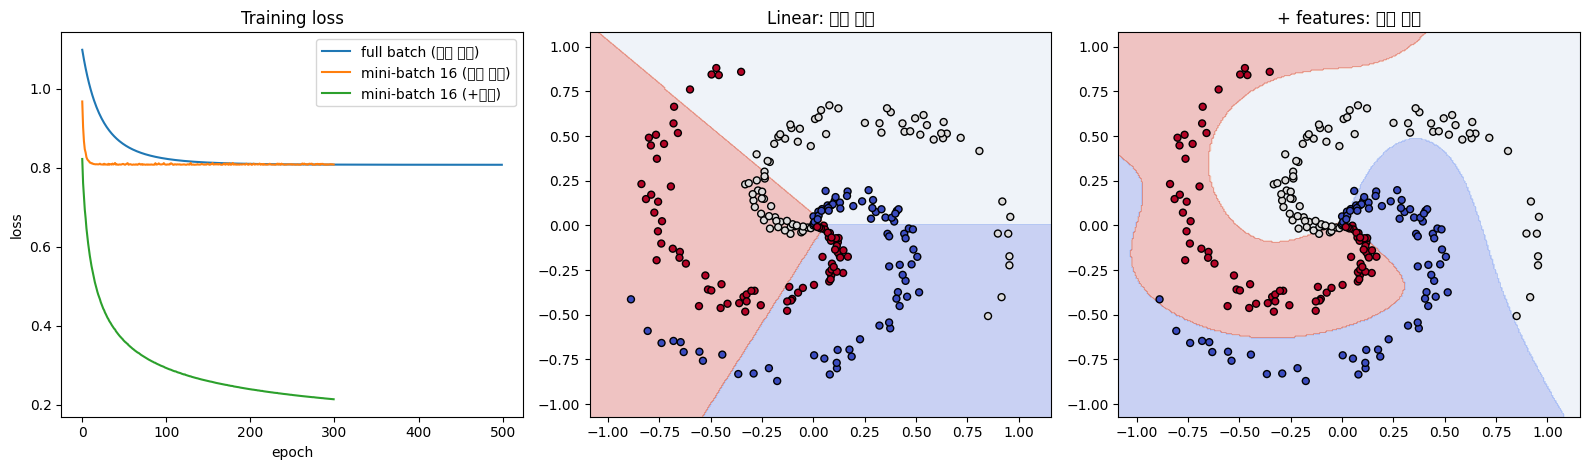

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

axes[0].plot(h1, label="full batch (원래 특성)")
axes[0].plot(h2, label="mini-batch 16 (원래 특성)")
axes[0].plot(h3, label="mini-batch 16 (+특성)")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss"); axes[0].legend()
axes[0].set_title("Training loss")

plot_boundary(X_train, labels_train, W2, b2, axes[1],
            title="Linear: 직선 경계")
plot_boundary(X_train, labels_train, W3, b3, axes[2], feat=add_features,
            title="+ features: 곡선 경계")
plt.tight_layout(); plt.show()

def spiral_feat(X):
    r = np.sqrt(X[:, 0]**2 + X[:, 1]**2)
    theta = np.arctan2(X[:, 0], X[:, 1])
    u = theta - 4 * r
    return np.c_[r, np.cos(u), np.sin(u)]            # (m, 3)

F_train, F_test = spiral_feat(X_train), spiral_feat(X_test)
W4, b4, h4 = train_batch(F_train, labels=labels_train, K=K, batch_size=16, lr=0.5, epochs=300)
print("3D 특성 test:", evaluate(F_test, labels_test, W4, b4))

plot_3d(F_train, labels_train, W4, b4, names=("r", "cos u", "sin u"), title="spiral in 3D")


In [ ]:
from mpl_toolkits.mplot3d import Axes3D   # 3D 축 등록용 (구버전 호환)

def plot_3d(F, labels, W, b, names=("f1", "f2", "f3"), title=""):
    """F: 학습에 쓴 3차원 특성 (m, 3), W: (K, 3), b: (K,)"""
    K = W.shape[0]
    fig = plt.figure(figsize=(7, 6))
    ax = fig.add_subplot(111, projection="3d")

    # 1) 데이터 점 (클래스별 색)
    ax.scatter(F[:, 0], F[:, 1], F[:, 2], c=labels, cmap="coolwarm",
            edgecolor="k", s=25, depthshade=True)

    # 2) 경계 평면: 클래스 쌍 (i, j)마다 하나씩
    lo, hi = F.min(axis=0), F.max(axis=0)
    g1, g2 = np.meshgrid(np.linspace(lo[0], hi[0], 30),
                        np.linspace(lo[1], hi[1], 30))

    for i in range(K):
        for j in range(i + 1, K):
            dw = W[i] - W[j]
            db = b[i] - b[j]
            if abs(dw[2]) < 1e-8:          # f3 방향 성분이 없으면 수직 평면이라 생략
                continue
            g3 = -(dw[0] * g1 + dw[1] * g2 + db) / dw[2]
            g3 = np.where((g3 >= lo[2]) & (g3 <= hi[2]), g3, np.nan)  # 데이터 범위 밖은 자르기
            ax.plot_surface(g1, g2, g3, alpha=0.25, linewidth=0, antialiased=False)

    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_xlabel(names[0]); ax.set_ylabel(names[1]); ax.set_zlabel(names[2])
    ax.set_title(title)
    plt.show()